In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions

utilities.set_plot_style()
%matplotlib inline

In [19]:
channels = ["base_ljDisplacementIso",
            'base_ljDisplacementIsohighPtID'
           ]

In [20]:
output_2mu = {}
output_4mu = {}
for channel_name in channels:
    
    output_signal_2mu = functions.load_output("signal_2mu", channel_name)
    output_signal_4mu = functions.load_output("signal_4mu", channel_name)
    output_2mu[channel_name] = output_signal_2mu
    output_4mu[channel_name] = output_signal_4mu

In [5]:
yaml_file_path = '../../configs/ntuples/signal_2mu2e_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())
masses = [200, 500, 800, 1000]
signals_2mu = [
    signal for signal in signals_all
    if any(f'{mass}GeV_' in signal for mass in masses)
]

yaml_file_path = '../../configs/ntuples/signal_4mu_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())
masses = [200, 500, 800, 1000]
signals_4mu = [
    signal for signal in signals_all
    if any(f'{mass}GeV_' in signal for mass in masses)
]

In [9]:
histogram_list = list(output_signal_2mu["out"][signals_2mu[0]]["hists"].keys())

for x in histogram_list:
    print(x)

mu_lj_pfMu_max_trkNumPixelHits
mu_lj_pfMu_min_trkNumPixelHits
mu_lj_pfMu_min_trkNumTrkLayers
mu_lj_muonN
mu_lj_pfMu_n
mu_lj_dsaMu_n
mu_lj_pt
mu_lj_muon_pt
mu_lj_pfMuon_pt
mu_lj_dsaMuon_pt
mu_lj_eta_phi


mu_lj_pfMu_max_trkNumPixelHits


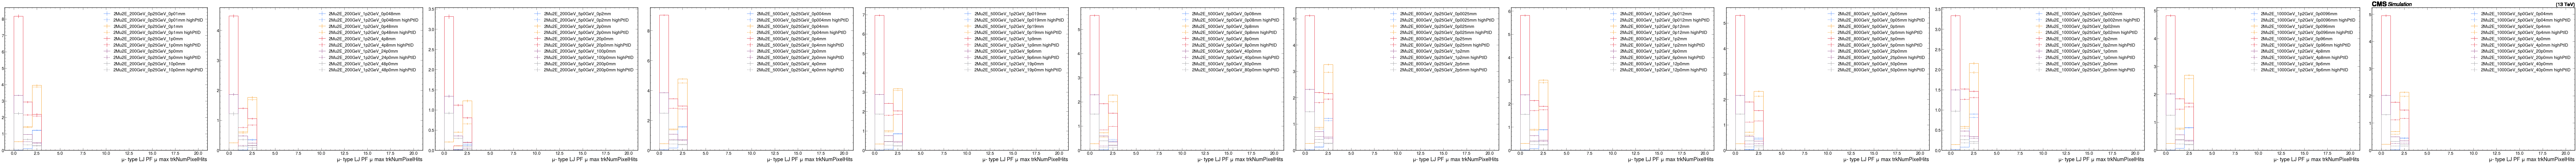

In [27]:
for histogram_name in histogram_list[:1]:
    print(histogram_name)

    fig, axs = plt.subplots(1, 12, figsize=(15 * 12, 12))

    for i in range(0, 60, 5):
        ax = axs[i // 5]

        for j in range(i, i + 5):
            try:
                histogram = output_2mu[channels[0]]["out"][signals_2mu[j]]["hists"][histogram_name][channels[0], :]
                utilities.plot(histogram, ax=ax, label=signals_2mu[j])
                color = ax.lines[-1].get_color()

                histogram = output_2mu[channels[1]]["out"][signals_2mu[j]]["hists"][histogram_name][channels[1], :]
                utilities.plot(histogram, ax=ax, label=f"{signals_2mu[j]} highPtID", linestyle="--", color =color)

            except Exception as e:
                print(f"Skipping {signals_2mu[j]}: {e}")
                continue

        ax.legend()

    plt.tight_layout()
    plt.show()

mu_lj_pfMu_max_trkNumPixelHits


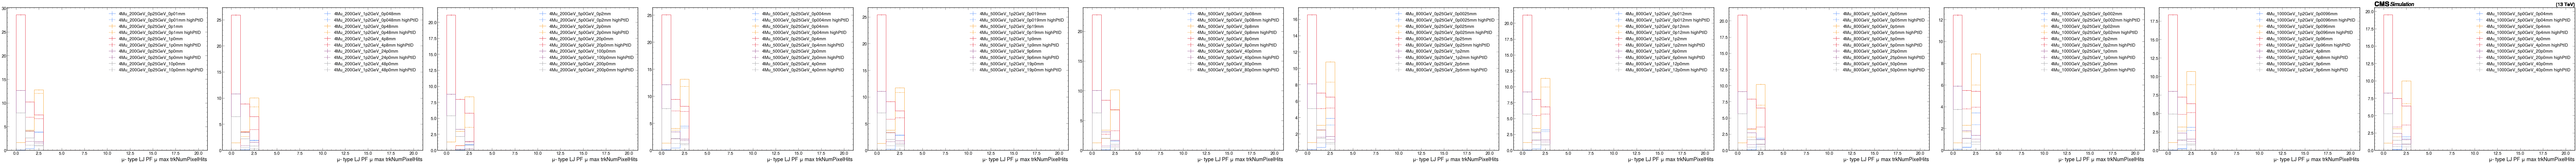

In [29]:
for histogram_name in histogram_list[:1]:
    print(histogram_name)

    fig, axs = plt.subplots(1, 12, figsize=(15 * 12, 12))

    for i in range(0, 60, 5):
        ax = axs[i // 5]

        for j in range(i, i + 5):
            try:
                histogram = output_4mu[channels[0]]["out"][signals_4mu[j]]["hists"][histogram_name][channels[0], :]
                utilities.plot(histogram, ax=ax, label=signals_4mu[j])
                color = ax.lines[-1].get_color()

                histogram = output_4mu[channels[1]]["out"][signals_4mu[j]]["hists"][histogram_name][channels[1], :]
                utilities.plot(histogram, ax=ax, label=f"{signals_4mu[j]} highPtID", linestyle="--", color =color)

            except Exception as e:
                print(f"Skipping {signals_4mu[j]}: {e}")
                continue

        ax.legend()

    plt.tight_layout()
    plt.show()